# Sensitivity of the results to the quenching threshold

An annulus is labelled quenched when its offset from the resolved star-forming main sequence,
`delta_sum_SFR = log Sigma_SFR - (0.7925 log Sigma_* - 7.572)`, falls below a threshold T
(baseline T = -2.4 dex; `Galaxy Partitioning - Annuli Revised.ipynb`, cell 11).
Here the classification and regression pipelines (halo-split notebooks, existing grids and seeds)
were rerun for several T with the rSFMS fit held fixed. Data: `../data/thresh_m<|T|>/`,
results: `../outputs/thresh_m<|T|>/`.

Caveats: the delta distribution has a sharp peak (~ -3.3 to -2.2 dex, likely a resolution floor), so cuts
below about -2.8 label almost nothing quenched and were not run. Hyperparameter grids were tuned at
T = -2.4 and reused. AUC and MSE are measured on different samples at each T, so they indicate
stability, not a like-for-like score. `all_satellites` and the DeltaSigma_SFR regression are not covered.

In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import spearmanr
from IPython.display import display

HERE = os.path.abspath('.')                      # run from threshold_test/analysis
ROOT = os.path.abspath(os.path.join(HERE, '..'))
OUTPUTS = os.path.join(ROOT, 'outputs')
FIG_DIR = os.path.join(HERE, 'figures')
TAB_DIR = os.path.join(HERE, 'tables')
for d in (FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

BASE = 'm2.4'                                    # baseline tag (T = -2.4)
SAMPLES = ['all_centrals', 'hms', 'lms']
SAMPLE_LABEL = {'all_centrals': 'All centrals', 'hms': 'High-mass satellites', 'lms': 'Low-mass satellites'}
MODELS = ['rf', 'xg']
MODEL_LABEL = {'rf': 'Random forest', 'xg': 'XGBoost'}
TASKS = {
    'classification': dict(imp='{s}_{m}_quenching_halosplit.csv', met='{s}_{m}_quenching_auc_halosplit.csv',
                           dir='{m}_classification_outputs'),
    'regression': dict(imp='{s}_{m}_reg_halosplit.csv', met='{s}_{m}_reg_mse_halosplit.csv',
                       dir='{m}_regression_outputs'),
}

# feature -> group, as in pubplots/combined_pubfigs_halosplit.ipynb
GROUP = {'bin_radii': 'Local', 'avg_s_mass': 'Local',
         's_mass': 'Intrinsic global', 'BHMass': 'Intrinsic global',
         'Mhalo': 'Environmental', 'overdens': 'Environmental'}
GROUPS = ['Local', 'Intrinsic global', 'Environmental']
FEATURES = list(GROUP)

# categorical slots 1-3 in fixed order; within a group features differ by marker + line style
GROUP_COLOR = {'Local': '#2a78d6', 'Intrinsic global': '#eb6834', 'Environmental': '#1baf7a'}
FEAT_STYLE = {'bin_radii': ('o', '-'), 'avg_s_mass': ('s', '--'),
              's_mass': ('o', '-'), 'BHMass': ('s', '--'),
              'Mhalo': ('o', '-'), 'overdens': ('s', '--')}
SAMPLE_COLOR = {'all_centrals': '#2a78d6', 'hms': '#eb6834', 'lms': '#1baf7a'}
MODEL_STYLE = {'rf': ('o', '-'), 'xg': ('s', '--')}

SURFACE, INK, INK2, GRID = '#ffffff', '#1a1a19', '#52514a', '#e4e3dc'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': GRID, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'normal', 'axes.titlecolor': INK,
    'legend.frameon': False, 'lines.linewidth': 1.6, 'lines.markersize': 5,
})


def tag_to_T(tag):
    return -float(tag[1:])


TAGS = sorted((d[len('thresh_'):] for d in os.listdir(OUTPUTS) if d.startswith('thresh_')),
              key=tag_to_T, reverse=True)          # loosest (-1.1) -> strictest
print('thresholds found:', [tag_to_T(t) for t in TAGS])

thresholds found: [-1.1, -1.4, -1.9, -2.0, -2.1, -2.2, -2.4, -2.6, -2.8]


## Distribution of delta_sum_SFR and the thresholds tested
Offset of each annulus's log Sigma_SFR from the fitted rSFMS, for the four annuli samples combined
(`../data/delta_sigma_sfr.parquet`, written by `make_variants.py`). Vertical lines mark the thresholds that were
run; an annulus is labelled quenched when its offset lies to the left of the line. The baseline (-2.4) and
Bluck's criterion (-1.1) are labelled.

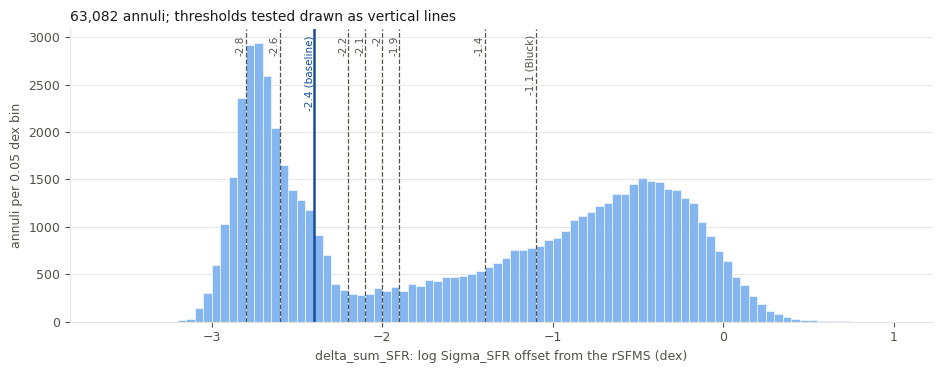

In [25]:
delta = pd.read_parquet(os.path.join(ROOT, 'data', 'delta_sigma_sfr.parquet'))['delta_sum_SFR']
BLUE_DARK = '#184f95'

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.hist(delta, bins=np.arange(-3.6, 1.01, 0.05), color='#86b6ef', edgecolor=SURFACE, linewidth=0.4)
ax.grid(axis='x', visible=False)
for tag in TAGS:
    T = tag_to_T(tag)
    is_base = tag == BASE
    ax.axvline(T, color=BLUE_DARK if is_base else INK2, lw=1.8 if is_base else 0.9, ls='-' if is_base else '--')
    note = ' (baseline)' if is_base else ' (Bluck)' if tag == 'm1.1' else ''
    ax.annotate(f'{T:g}{note}', (T, 0.98), xycoords=('data', 'axes fraction'), rotation=90, ha='right', va='top',
                fontsize=7.5, color=BLUE_DARK if is_base else INK2)
ax.set_xlabel('delta_sum_SFR: log Sigma_SFR offset from the rSFMS (dex)')
ax.set_ylabel('annuli per 0.05 dex bin')
ax.set_title(f'{len(delta):,} annuli; thresholds tested drawn as vertical lines', loc='left')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'delta_sigma_sfr_thresholds.pdf'), bbox_inches='tight')
plt.show()

## 1. Load results

In [26]:
imp_rows, met_rows, missing = [], [], []
for tag in TAGS:
    for task, cfg in TASKS.items():
        for m in MODELS:
            for s in SAMPLES:
                d = os.path.join(OUTPUTS, f'thresh_{tag}', cfg['dir'].format(m=m))
                fi = os.path.join(d, cfg['imp'].format(s=s, m=m))
                fm = os.path.join(d, cfg['met'].format(s=s, m=m))
                if not (os.path.exists(fi) and os.path.exists(fm)):
                    missing.append((tag, task, m, s))
                    continue
                df = pd.read_csv(fi)
                df = df.rename(columns={'Feature': 'feature', 'Mean Importance': 'mean', 'Std Dev': 'std'})
                df = df.assign(tag=tag, T=tag_to_T(tag), task=task, model=m, sample=s)
                df['group'] = df['feature'].map(GROUP)
                imp_rows.append(df)
                mt = pd.read_csv(fm).iloc[0]
                met_rows.append(dict(tag=tag, T=tag_to_T(tag), task=task, model=m, sample=s,
                                     train=mt.iloc[0], test=mt.iloc[1]))
imp = pd.concat(imp_rows, ignore_index=True)
met = pd.DataFrame(met_rows)
assert imp['group'].notna().all(), imp.loc[imp['group'].isna(), 'feature'].unique()
print(f'{len(imp):,} importance rows, {len(met)} metric rows;',
      f'{len(missing)} of {len(TAGS) * 12} (threshold, notebook) results not available yet')
if missing:
    print('incomplete thresholds:', sorted({tag_to_T(t[0]) for t in missing}, reverse=True))

648 importance rows, 108 metric rows; 0 of 108 (threshold, notebook) results not available yet


## 2. Sample sizes and class balance
The threshold moves the quenched fraction a lot, and sets the size of the star-forming sample that enters
the regression. `low-N` (section 7) marks cases with fewer than 500 annuli in the minority class
(classification) or fewer than 2,500 star-forming annuli (regression); these are heuristic flags, not tested limits.

In [27]:
cc = pd.read_csv(os.path.join(ROOT, 'data', 'class_counts.csv'))
SAMPLE_PARTS = {'all_centrals': ['low_mass_central', 'high_mass_central'],
                'hms': ['high_mass_satellite'], 'lms': ['low_mass_satellite']}
rows = []
for s, parts in SAMPLE_PARTS.items():
    g = cc[cc['sample'].isin(parts)].groupby('threshold')[['n', 'n_quenched']].sum().reset_index()
    g['sample_key'] = s
    rows.append(g)
counts = pd.concat(rows)
counts['n_sf'] = counts['n'] - counts['n_quenched']
counts['frac_quenched'] = (counts['n_quenched'] / counts['n']).round(3)
counts['minority'] = counts[['n_quenched', 'n_sf']].min(axis=1)
counts = counts.sort_values(['sample_key', 'threshold'], ascending=[True, False])
counts.to_csv(os.path.join(TAB_DIR, 'sample_counts.csv'), index=False)
tbl = counts.pivot(index='threshold', columns='sample_key', values=['n_quenched', 'n_sf', 'frac_quenched'])
display(tbl.sort_index(ascending=False))

n_quenched                         n_sf                  \
sample_key all_centrals     hms     lms all_centrals     hms     lms   
threshold                                                              
-1.1            25752.0  6485.0  2589.0      22824.0  2190.0  3242.0   
-1.4            22439.0  5959.0  2264.0      26137.0  2716.0  3567.0   
-1.9            18889.0  5352.0  2003.0      29687.0  3323.0  3828.0   
-2.0            18325.0  5259.0  1964.0      30251.0  3416.0  3867.0   
-2.1            17818.0  5159.0  1930.0      30758.0  3516.0  3901.0   
-2.2            17364.0  5059.0  1909.0      31212.0  3616.0  3922.0   
-2.4            15623.0  4493.0  1867.0      32953.0  4182.0  3964.0   
-2.6            11782.0  2959.0  1741.0      36794.0  5716.0  4090.0   
-2.8             4521.0   449.0  1026.0      44055.0  8226.0  4805.0   

           frac_quenched                
sample_key  all_centrals    hms    lms  
threshold                               
-1.1               0.530  0.748  0.444  
-1.4               0.462  0.687  0.388  
-1.9               0.389  0.617  0.344  
-2.0               0.377  0.606  0.337  
-2.1               0.367  0.595  0.331  
-2.2               0.357  0.583  0.327  
-2.4               0.322  0.518  0.320  
-2.6               0.243  0.341  0.299  
-2.8               0.093  0.052  0.176

## 3. Held-out performance versus threshold
Test AUC (classification) and test MSE of `avg_SFR` on star-forming annuli (regression), mean over the 10
seeds, as stored in the metric CSVs (rounded to 2 decimals by the notebooks).

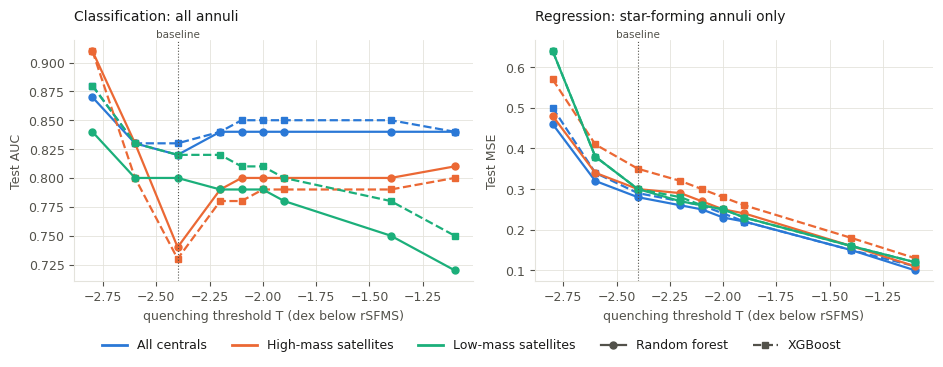

T                                  -1.1  -1.4  -1.9  -2.0  -2.1  -2.2  -2.4  \
task           model sample                                                   
classification rf    all_centrals  0.84  0.84  0.84  0.84  0.84  0.84  0.82   
                     hms           0.81  0.80  0.80  0.80  0.80  0.79  0.74   
                     lms           0.72  0.75  0.78  0.79  0.79  0.79  0.80   
               xg    all_centrals  0.84  0.85  0.85  0.85  0.85  0.84  0.83   
                     hms           0.80  0.79  0.79  0.79  0.78  0.78  0.73   
                     lms           0.75  0.78  0.80  0.81  0.81  0.82  0.82   
regression     rf    all_centrals  0.10  0.15  0.22  0.23  0.25  0.26  0.28   
                     hms           0.11  0.16  0.24  0.25  0.27  0.29  0.30   
                     lms           0.12  0.16  0.23  0.25  0.26  0.27  0.30   
               xg    all_centrals  0.11  0.15  0.22  0.24  0.26  0.27  0.29   
                     hms           0.13  0.18  0.26  0.28  0.30  0.32  0.35   
                     lms           0.12  0.16  0.23  0.25  0.26  0.28  0.30   

T                                  -2.6  -2.8  
task           model sample                    
classification rf    all_centrals  0.83  0.87  
                     hms           0.83  0.91  
                     lms           0.80  0.84  
               xg    all_centrals  0.83  0.88  
                     hms           0.80  0.91  
                     lms           0.83  0.88  
regression     rf    all_centrals  0.32  0.46  
                     hms           0.34  0.48  
                     lms           0.38  0.64  
               xg    all_centrals  0.34  0.50  
                     hms           0.41  0.57  
                     lms           0.38  0.64

In [28]:
def mark_baseline(ax, label=True):
    ax.axvline(-2.4, color=INK2, lw=0.8, ls=':')
    if label:
        ax.annotate('baseline', (-2.4, 1.0), xycoords=('data', 'axes fraction'), ha='center', va='bottom',
                    fontsize=7.5, color=INK2)


def metric_figure(fname):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharex=True)
    for ax, (task, ylab) in zip(axes, [('classification', 'Test AUC'), ('regression', 'Test MSE')]):
        for s in SAMPLES:
            for m in MODELS:
                d = met[(met.task == task) & (met['sample'] == s) & (met.model == m)].sort_values('T')
                mk, ls = MODEL_STYLE[m]
                ax.plot(d['T'], d['test'], color=SAMPLE_COLOR[s], marker=mk, ls=ls)
        mark_baseline(ax)
        ax.set_xlabel('quenching threshold T (dex below rSFMS)')
        ax.set_ylabel(ylab)
        ax.set_title('Classification: all annuli' if task == 'classification' else 'Regression: star-forming annuli only',
                     loc='left', pad=14)
    handles = [Line2D([], [], color=SAMPLE_COLOR[s], lw=2, label=SAMPLE_LABEL[s]) for s in SAMPLES]
    handles += [Line2D([], [], color=INK2, marker=MODEL_STYLE[m][0], ls=MODEL_STYLE[m][1], label=MODEL_LABEL[m])
                for m in MODELS]
    fig.legend(handles=handles, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches='tight')
    return fig


fig = metric_figure('metrics_vs_threshold.pdf')
plt.show()
perf = met.pivot_table(index=['task', 'model', 'sample'], columns='T', values='test').sort_index(axis=1, ascending=False)
perf.to_csv(os.path.join(TAB_DIR, 'test_metric_by_threshold.csv'))
display(perf.round(2))

## 4. Feature importance by group versus threshold
Importances are the mean over seeds; each bar sums the importances of the features in a group
(local: `bin_radii`, `avg_s_mass`; intrinsic global: `s_mass`, `BHMass`; environmental: `Mhalo`, `overdens`).

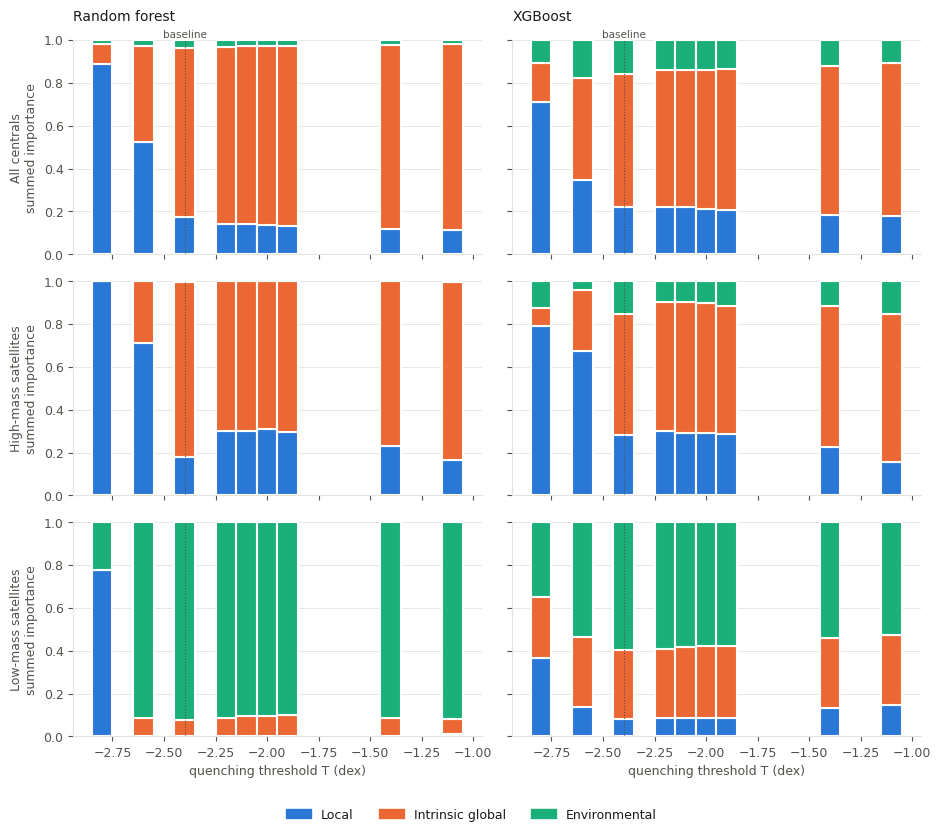

In [29]:
def group_figure(task, fname):
    fig, axes = plt.subplots(len(SAMPLES), len(MODELS), figsize=(9.5, 8.2), sharex=True, sharey=True)
    for i, s in enumerate(SAMPLES):
        for j, m in enumerate(MODELS):
            ax = axes[i, j]
            d = imp[(imp.task == task) & (imp['sample'] == s) & (imp.model == m)]
            g = d.groupby(['T', 'group'])['mean'].sum().unstack().reindex(columns=GROUPS)
            bottom = np.zeros(len(g))
            for grp in GROUPS:
                ax.bar(g.index, g[grp], width=0.1, bottom=bottom, color=GROUP_COLOR[grp],
                       edgecolor=SURFACE, linewidth=1.5)
                bottom += g[grp].values
            mark_baseline(ax, label=(i == 0))
            ax.set_ylim(0, 1)
            ax.grid(axis='x', visible=False)
            if i == 0:
                ax.set_title(MODEL_LABEL[m], loc='left', pad=14)
            if j == 0:
                ax.set_ylabel(SAMPLE_LABEL[s] + '\nsummed importance')
            if i == len(SAMPLES) - 1:
                ax.set_xlabel('quenching threshold T (dex)')
    fig.legend(handles=[Patch(color=GROUP_COLOR[g], label=g) for g in GROUPS], loc='lower center',
               ncol=3, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches='tight')
    return fig


group_figure('classification', 'group_importance_classification.pdf')
plt.show()

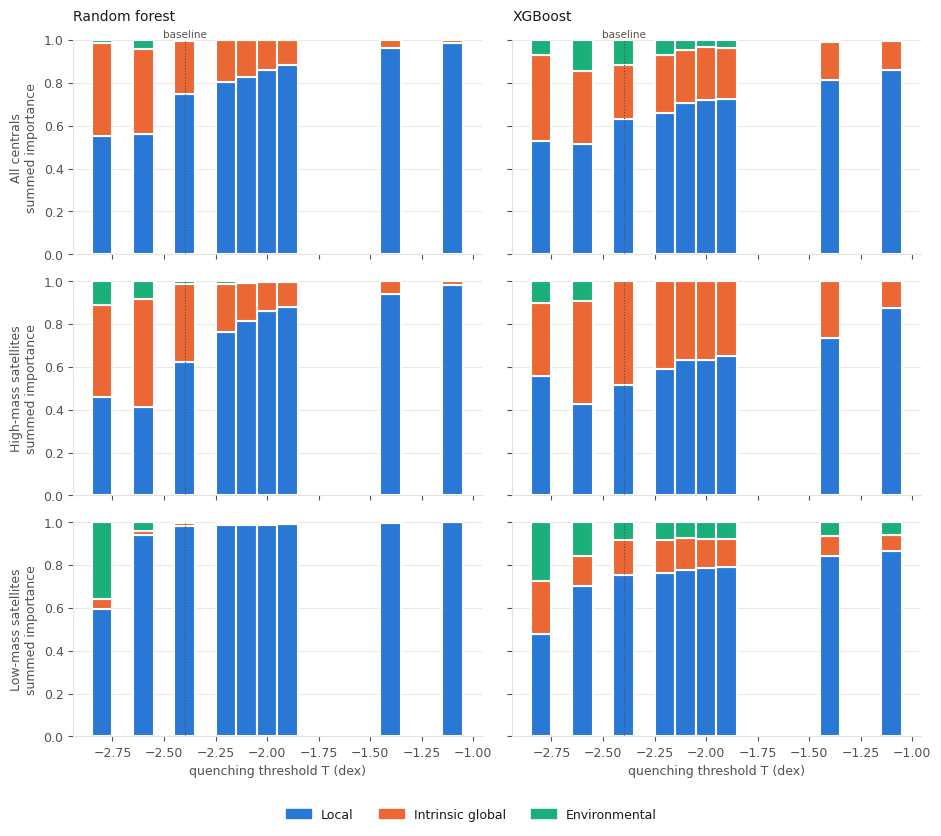

In [30]:
group_figure('regression', 'group_importance_regression.pdf')
plt.show()

## 5. Individual feature importance versus threshold
Lines are the mean over seeds; the band is one standard deviation across seeds. Colour is the feature's group,
circles/solid and squares/dashed distinguish the two features within a group.

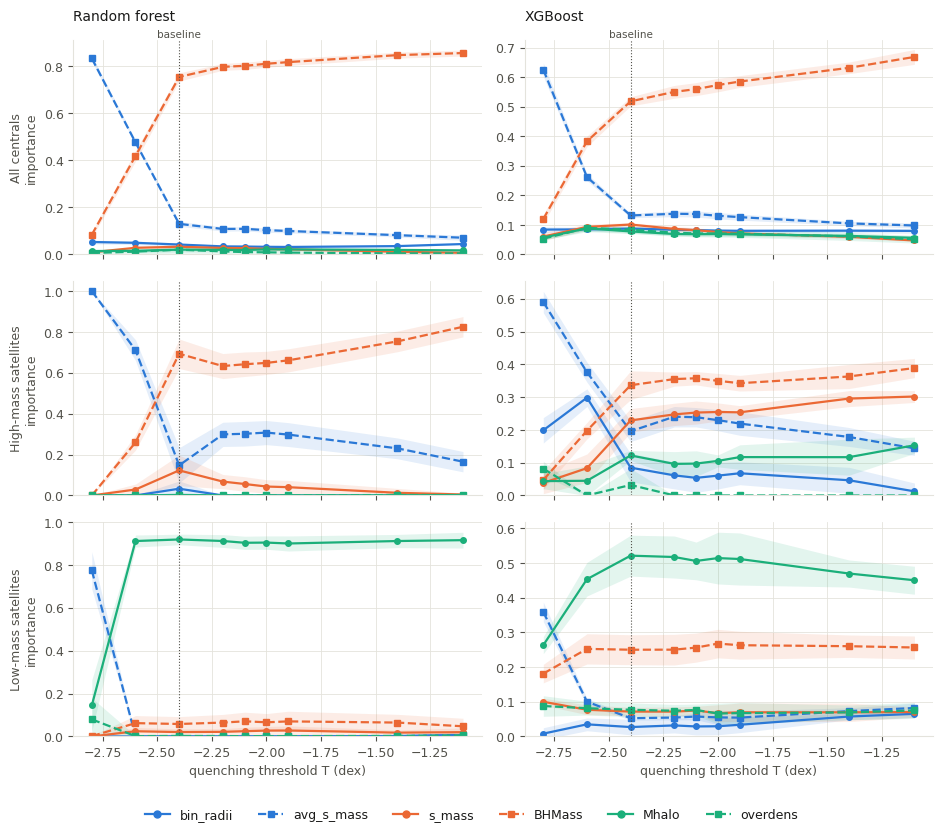

In [31]:
def feature_figure(task, fname):
    fig, axes = plt.subplots(len(SAMPLES), len(MODELS), figsize=(9.5, 8.2), sharex=True)
    for i, s in enumerate(SAMPLES):
        for j, m in enumerate(MODELS):
            ax = axes[i, j]
            d = imp[(imp.task == task) & (imp['sample'] == s) & (imp.model == m)]
            for f in FEATURES:
                x = d[d.feature == f].sort_values('T')
                mk, ls = FEAT_STYLE[f]
                c = GROUP_COLOR[GROUP[f]]
                ax.fill_between(x['T'], x['mean'] - x['std'], x['mean'] + x['std'], color=c, alpha=0.12, lw=0)
                ax.plot(x['T'], x['mean'], color=c, marker=mk, ls=ls, ms=4)
            mark_baseline(ax, label=(i == 0))
            ax.set_ylim(bottom=0)
            if i == 0:
                ax.set_title(MODEL_LABEL[m], loc='left', pad=14)
            if j == 0:
                ax.set_ylabel(SAMPLE_LABEL[s] + '\nimportance')
            if i == len(SAMPLES) - 1:
                ax.set_xlabel('quenching threshold T (dex)')
    handles = [Line2D([], [], color=GROUP_COLOR[GROUP[f]], marker=FEAT_STYLE[f][0], ls=FEAT_STYLE[f][1], label=f)
               for f in FEATURES]
    fig.legend(handles=handles, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches='tight')
    return fig


feature_figure('classification', 'feature_importance_classification.pdf')
plt.show()

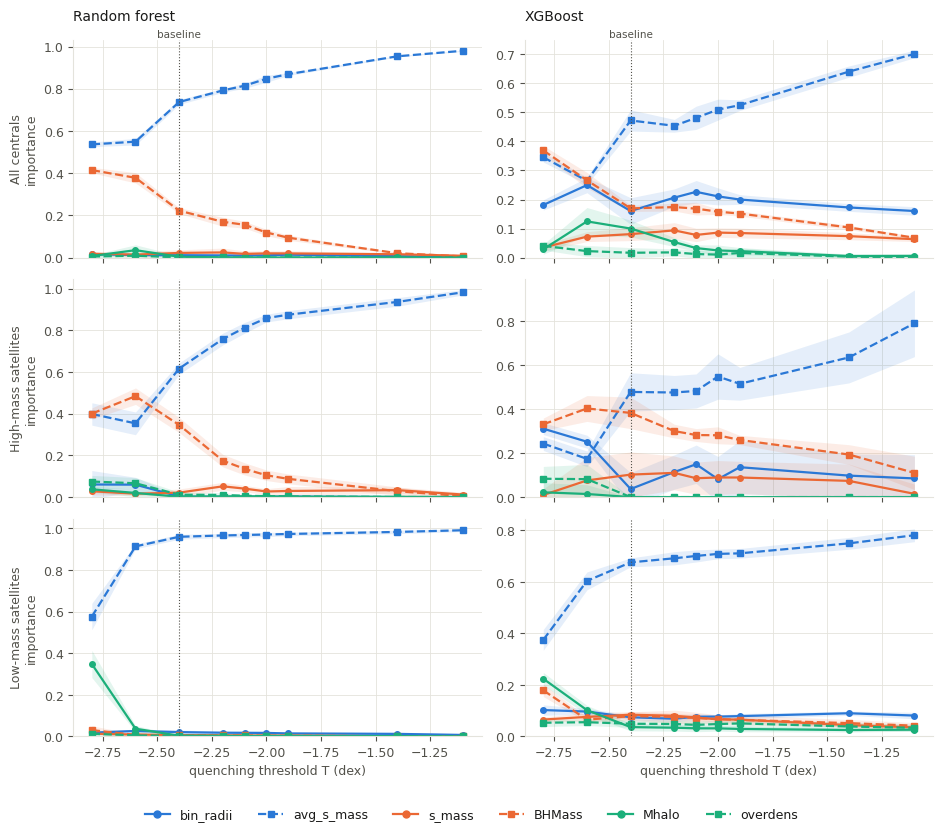

In [32]:
feature_figure('regression', 'feature_importance_regression.pdf')
plt.show()

## 6. Stability against the baseline
For each task, model and sample and each threshold: Spearman rank correlation of the six feature importances
with the baseline ranking, whether the ordering of the three groups matches the baseline, and the most
important feature. With six features a rank correlation is coarse (one swap of neighbours gives 0.94).

In [33]:
def group_order(d):
    return tuple(d.groupby('group')['mean'].sum().sort_values(ascending=False).index)


rows = []
for (task, m, s), d in imp.groupby(['task', 'model', 'sample']):
    b = d[d.tag == BASE].set_index('feature')['mean'].reindex(FEATURES)
    b_order, b_top = group_order(d[d.tag == BASE]), b.idxmax()
    for tag, dt in d.groupby('tag'):
        v = dt.set_index('feature')['mean'].reindex(FEATURES)
        rho = spearmanr(b, v).correlation
        rows.append(dict(task=task, model=m, sample=s, T=tag_to_T(tag), rho=rho,
                         group_order_same=(group_order(dt) == b_order), top_feature=v.idxmax(),
                         top_same=(v.idxmax() == b_top), top_share=v.max()))
stab = pd.DataFrame(rows)
stab.to_csv(os.path.join(TAB_DIR, 'stability_vs_baseline.csv'), index=False)

rho_tbl = stab.pivot_table(index=['task', 'model', 'sample'], columns='T', values='rho').sort_index(axis=1, ascending=False)
display(rho_tbl.round(2))
top_tbl = stab.pivot_table(index=['task', 'model', 'sample'], columns='T', values='top_feature', aggfunc='first')
display(top_tbl.sort_index(axis=1, ascending=False))

T                                  -1.1  -1.4  -1.9  -2.0  -2.1  -2.2  -2.4  \
task           model sample                                                   
classification rf    all_centrals  0.83  0.83  0.94  0.94  0.94  0.94   1.0   
                     hms           0.83  0.77  0.77  0.77  0.83  0.83   1.0   
                     lms           0.83  0.94  1.00  1.00  1.00  1.00   1.0   
               xg    all_centrals  0.60  0.60  0.94  0.94  0.94  1.00   1.0   
                     hms           0.94  1.00  1.00  1.00  1.00  1.00   1.0   
                     lms           0.83  0.77  0.94  0.94  1.00  1.00   1.0   
regression     rf    all_centrals  0.94  1.00  0.94  0.94  1.00  1.00   1.0   
                     hms           0.77  0.77  1.00  0.94  0.94  0.94   1.0   
                     lms           0.83  0.77  1.00  1.00  1.00  1.00   1.0   
               xg    all_centrals  0.89  0.89  0.89  0.89  0.89  0.89   1.0   
                     hms           0.94  0.94  0.94  1.00  0.94  0.94   1.0   
                     lms           0.77  0.77  0.83  0.77  0.83  1.00   1.0   

T                                  -2.6  -2.8  
task           model sample                    
classification rf    all_centrals  0.89  0.77  
                     hms           0.77  0.09  
                     lms           1.00  0.26  
               xg    all_centrals  0.83  0.83  
                     hms           0.37 -0.37  
                     lms           0.83  0.37  
regression     rf    all_centrals  0.83  1.00  
                     hms           0.60  0.60  
                     lms           0.66  0.49  
               xg    all_centrals  0.94  0.71  
                     hms           0.55  0.41  
                     lms           0.26  0.26

T                                        -1.1        -1.4        -1.9  \
task           model sample                                             
classification rf    all_centrals      BHMass      BHMass      BHMass   
                     hms               BHMass      BHMass      BHMass   
                     lms                Mhalo       Mhalo       Mhalo   
               xg    all_centrals      BHMass      BHMass      BHMass   
                     hms               BHMass      BHMass      BHMass   
                     lms                Mhalo       Mhalo       Mhalo   
regression     rf    all_centrals  avg_s_mass  avg_s_mass  avg_s_mass   
                     hms           avg_s_mass  avg_s_mass  avg_s_mass   
                     lms           avg_s_mass  avg_s_mass  avg_s_mass   
               xg    all_centrals  avg_s_mass  avg_s_mass  avg_s_mass   
                     hms           avg_s_mass  avg_s_mass  avg_s_mass   
                     lms           avg_s_mass  avg_s_mass  avg_s_mass   

T                                        -2.0        -2.1        -2.2  \
task           model sample                                             
classification rf    all_centrals      BHMass      BHMass      BHMass   
                     hms               BHMass      BHMass      BHMass   
                     lms                Mhalo       Mhalo       Mhalo   
               xg    all_centrals      BHMass      BHMass      BHMass   
                     hms               BHMass      BHMass      BHMass   
                     lms                Mhalo       Mhalo       Mhalo   
regression     rf    all_centrals  avg_s_mass  avg_s_mass  avg_s_mass   
                     hms           avg_s_mass  avg_s_mass  avg_s_mass   
                     lms           avg_s_mass  avg_s_mass  avg_s_mass   
               xg    all_centrals  avg_s_mass  avg_s_mass  avg_s_mass   
                     hms           avg_s_mass  avg_s_mass  avg_s_mass   
                     lms           avg_s_mass  avg_s_mass  avg_s_mass   

T                                        -2.4        -2.6        -2.8  
task           model sample                                            
classification rf    all_centrals      BHMass  avg_s_mass  avg_s_mass  
                     hms               BHMass  avg_s_mass  avg_s_mass  
                     lms                Mhalo       Mhalo  avg_s_mass  
               xg    all_centrals      BHMass      BHMass  avg_s_mass  
                     hms               BHMass  avg_s_mass  avg_s_mass  
                     lms                Mhalo       Mhalo  avg_s_mass  
regression     rf    all_centrals  avg_s_mass  avg_s_mass  avg_s_mass  
                     hms           avg_s_mass      BHMass      BHMass  
                     lms           avg_s_mass  avg_s_mass  avg_s_mass  
               xg    all_centrals  avg_s_mass      BHMass      BHMass  
                     hms           avg_s_mass      BHMass      BHMass  
                     lms           avg_s_mass  avg_s_mass  avg_s_mass

## 7. Group ordering versus threshold
Does the ranking of the three feature groups (L = local, I = intrinsic global, E = environmental, by summed
importance) match the baseline ranking? `RANGE_MIN` sets which thresholds count: cuts at or above it are
outside the quenched peak; stricter cuts are still tabulated but reported separately.
`gap` is the smallest difference in summed importance between adjacent groups at that threshold, so a
mismatch with a small gap is a near-tie rather than a real reordering (no tolerance is applied).

In [34]:
RANGE_MIN = -2.4          # thresholds below this lie inside the quenched peak
ABBR = {'Local': 'L', 'Intrinsic global': 'I', 'Environmental': 'E'}

rows = []
for (task, m, s, tag), d in imp.groupby(['task', 'model', 'sample', 'tag']):
    shares = d.groupby('group')['mean'].sum().reindex(GROUPS).sort_values(ascending=False)
    rows.append(dict(task=task, model=m, sample=s, T=tag_to_T(tag), order=tuple(shares.index),
                     order_str=''.join(ABBR[g] for g in shares.index), lead_share=shares.iloc[0],
                     gap=float(-np.diff(shares.values).max())))   # smallest adjacent difference
go = pd.DataFrame(rows)
base_order = go[np.isclose(go['T'], tag_to_T(BASE))].set_index(['task', 'model', 'sample'])['order']
go['same_as_baseline'] = [o == base_order[(t, m, s)] for o, t, m, s in
                          zip(go['order'], go['task'], go['model'], go['sample'])]
go['in_range'] = go['T'] >= RANGE_MIN - 1e-9
go.drop(columns='order').to_csv(os.path.join(TAB_DIR, 'group_order_by_threshold.csv'), index=False)

# ordering at each threshold, with the share held by the leading group
go['cell'] = go['order_str'] + ' (' + go['lead_share'].round(2).astype(str) + ')'
display(go.pivot_table(index=['task', 'model', 'sample'], columns='T', values='cell', aggfunc='first')
          .sort_index(axis=1, ascending=False))

T                                        -1.1        -1.4        -1.9  \
task           model sample                                             
classification rf    all_centrals  ILE (0.86)  ILE (0.86)  ILE (0.84)   
                     hms           ILE (0.83)  ILE (0.77)   ILE (0.7)   
                     lms           EIL (0.92)  EIL (0.91)   EIL (0.9)   
               xg    all_centrals  ILE (0.72)  ILE (0.69)  ILE (0.66)   
                     hms           ILE (0.69)  ILE (0.66)   ILE (0.6)   
                     lms           EIL (0.53)  EIL (0.54)  EIL (0.58)   
regression     rf    all_centrals  LIE (0.98)  LIE (0.96)  LIE (0.88)   
                     hms           LIE (0.98)  LIE (0.94)  LIE (0.88)   
                     lms            LIE (1.0)   LEI (1.0)  LIE (0.99)   
               xg    all_centrals  LIE (0.86)  LIE (0.81)  LIE (0.72)   
                     hms           LIE (0.88)  LIE (0.73)  LIE (0.65)   
                     lms           LIE (0.86)  LIE (0.84)  LIE (0.79)   

T                                        -2.0        -2.1        -2.2  \
task           model sample                                             
classification rf    all_centrals  ILE (0.83)  ILE (0.83)  ILE (0.83)   
                     hms           ILE (0.69)   ILE (0.7)   ILE (0.7)   
                     lms           EIL (0.91)   EIL (0.9)  EIL (0.91)   
               xg    all_centrals  ILE (0.65)  ILE (0.64)  ILE (0.64)   
                     hms            ILE (0.6)  ILE (0.61)   ILE (0.6)   
                     lms           EIL (0.58)  EIL (0.58)  EIL (0.59)   
regression     rf    all_centrals  LIE (0.86)  LIE (0.82)   LIE (0.8)   
                     hms           LIE (0.86)  LIE (0.81)  LIE (0.76)   
                     lms           LIE (0.99)  LIE (0.99)  LIE (0.98)   
               xg    all_centrals  LIE (0.72)  LIE (0.71)  LIE (0.66)   
                     hms           LIE (0.63)  LIE (0.63)  LIE (0.59)   
                     lms           LIE (0.79)  LIE (0.78)  LIE (0.76)   

T                                        -2.4        -2.6        -2.8  
task           model sample                                            
classification rf    all_centrals  ILE (0.79)  LIE (0.53)  LIE (0.89)  
                     hms           ILE (0.82)  LIE (0.71)   LEI (1.0)  
                     lms           EIL (0.92)  EIL (0.91)  LEI (0.77)  
               xg    all_centrals  ILE (0.62)  ILE (0.48)  LIE (0.71)  
                     hms           ILE (0.57)  LIE (0.67)  LEI (0.79)  
                     lms            EIL (0.6)  EIL (0.54)  LEI (0.37)  
regression     rf    all_centrals  LIE (0.75)  LIE (0.56)  LIE (0.55)  
                     hms           LIE (0.62)   ILE (0.5)  LIE (0.46)  
                     lms           LIE (0.98)  LEI (0.94)  LEI (0.59)  
               xg    all_centrals  LIE (0.63)  LIE (0.51)  LIE (0.53)  
                     hms           LIE (0.51)  ILE (0.48)  LIE (0.55)  
                     lms           LIE (0.75)   LEI (0.7)  LEI (0.48)

In [35]:
summ_rows = []
for (task, m, s), d in go.groupby(['task', 'model', 'sample']):
    d = d.sort_values('T', ascending=False)
    r, out = d[d.in_range], d[~d.in_range]

    def fmt(x):
        return ', '.join(f"{t.T:g} ({t.order_str}, gap {t.gap:.2f})" for t in x.itertuples()) or '-'

    summ_rows.append({'task': task, 'model': m, 'sample': s,
                      'baseline order': ''.join(ABBR[g] for g in base_order[(task, m, s)]),
                      f'kept for T >= {RANGE_MIN:g}': f"{int(r.same_as_baseline.sum())}/{len(r)}",
                      'differs (in range)': fmt(r[~r.same_as_baseline]),
                      'differs (stricter)': fmt(out[~out.same_as_baseline])})
group_summary = pd.DataFrame(summ_rows)
group_summary.to_csv(os.path.join(TAB_DIR, 'group_order_summary.csv'), index=False)
display(group_summary)

,task,model,sample,baseline order,kept for T >= -2.4,differs (in range),differs (stricter)
0,classification,rf,all_centrals,ILE,7/7,-,"-2.6 (LIE, gap 0.08), -2.8 (LIE, gap 0.07)"
1,classification,rf,hms,ILE,7/7,-,"-2.6 (LIE, gap 0.29), -2.8 (LEI, gap 0.00)"
2,classification,rf,lms,EIL,7/7,-,"-2.8 (LEI, gap 0.22)"
3,classification,xg,all_centrals,ILE,7/7,-,"-2.8 (LIE, gap 0.07)"
4,classification,xg,hms,ILE,7/7,-,"-2.6 (LIE, gap 0.24), -2.8 (LEI, gap 0.04)"
5,classification,xg,lms,EIL,7/7,-,"-2.8 (LEI, gap 0.02)"
6,regression,rf,all_centrals,LIE,7/7,-,-
7,regression,rf,hms,LIE,7/7,-,"-2.6 (ILE, gap 0.09)"
8,regression,rf,lms,LIE,6/7,"-1.4 (LEI, gap 0.00)","-2.6 (LEI, gap 0.03), -2.8 (LEI, gap 0.23)"
9,regression,xg,all_centrals,LIE,7/7,-,-


## 8. Summary
One row per task/model/sample. `min rho` is the worst rank correlation with the baseline over the thresholds,
`group order kept` counts thresholds (including the baseline itself) at which the group ranking equals the
baseline ranking, and `top feature changes at` lists the thresholds where the most important feature differs.
`low-N at` lists thresholds flagged in section 2.

In [36]:
def low_n(task, s, T):
    r = counts[(counts.sample_key == s) & (np.isclose(counts.threshold, T))].iloc[0]
    return (r.minority < 500) if task == 'classification' else (r.n_sf < 2500)


rows = []
for (task, m, s), d in stab.groupby(['task', 'model', 'sample']):
    d = d.sort_values('T', ascending=False)
    rows.append({
        'task': task, 'model': m, 'sample': s,
        'min rho': round(d['rho'].min(), 2),
        'group order kept': f"{int(d.group_order_same.sum())}/{len(d)}",
        'top feature changes at': ', '.join(f"{t:g}" for t in d.loc[~d.top_same, 'T']) or '-',
        'low-N at': ', '.join(f"{t:g}" for t in d['T'] if low_n(task, s, t)) or '-',
    })
summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(TAB_DIR, 'summary.csv'), index=False)
display(summary)
print('thresholds in the analysis:', sorted(set(stab['T']), reverse=True))
print('thresholds with missing results (partial or absent):', sorted({tag_to_T(t[0]) for t in missing}, reverse=True))

,task,model,sample,min rho,group order kept,top feature changes at,low-N at
0,classification,rf,all_centrals,0.77,7/9,"-2.6, -2.8",-
1,classification,rf,hms,0.09,7/9,"-2.6, -2.8",-2.8
2,classification,rf,lms,0.26,8/9,-2.8,-
3,classification,xg,all_centrals,0.60,8/9,-2.8,-
4,classification,xg,hms,-0.37,7/9,"-2.6, -2.8",-2.8
5,classification,xg,lms,0.37,8/9,-2.8,-
6,regression,rf,all_centrals,0.83,9/9,-,-
7,regression,rf,hms,0.60,8/9,"-2.6, -2.8",-1.1
8,regression,rf,lms,0.49,6/9,-,-
9,regression,xg,all_centrals,0.71,9/9,"-2.6, -2.8",-


thresholds in the analysis: [-1.1, -1.4, -1.9, -2.0, -2.1, -2.2, -2.4, -2.6, -2.8]
thresholds with missing results (partial or absent): []
